# IT5092 — Neuroscience & Neurocomputing
### Assignment: Spiking Neural Network for MNIST Digit Classification

---

In [ ]:
# ============================================================
# Cell 1: Install dependencies (run once if needed)
# ============================================================
# Uncomment and run this cell if you are missing any packages:
# !pip install brian2 scikit-learn matplotlib numpy

In [ ]:
# ============================================================
# Cell 2: Imports and Setup — PROVIDED
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
import sys, os

# Add assignment root to path so we can import config and utils
sys.path.insert(0, os.path.dirname(os.path.abspath('__file__')))

import config
from config import *

# Brian2
import brian2 as b2
from brian2 import *
from brian2.utils.logger import BrianLogger

# Brian2 settings
prefs.codegen.target = 'numpy'          # use numpy backend (no C++ compiler needed)
BrianLogger.suppress_hierarchy('brian2') # suppress verbose Brian2 logs
defaultclock.dt = DT * ms              # set simulation timestep from config

# Reproducibility
np.random.seed(RANDOM_SEED)

# Provided utilities
from utils.mnist_loader import load_mnist, show_sample_images
from utils.metrics import assign_neuron_labels, predict_from_spikes, compute_accuracy, classification_report_snn
from utils.plotting import (plot_spike_raster, plot_weight_receptive_fields,
                             plot_firing_rate_distribution, plot_training_progress,
                             plot_neuron_assignments)

print("All imports successful.")
print(f"Brian2 version: {b2.__version__}")

All imports successful.
Brian2 version: 2.10.1


---
## Section 0: Brian2 Quick Introduction

Brian2 is a Python simulator for spiking neural networks. Before building the full MNIST network, work through this mini-tutorial to get comfortable with the Brian2 syntax.

### Key Brian2 objects you will use:

| Object | Purpose |
|--------|---------|
| `NeuronGroup` | A population of neurons sharing the same differential equations |
| `PoissonGroup` | Input neurons that fire at a specified rate (Poisson process) |
| `Synapses` | Connections between neuron groups (can have plasticity rules) |
| `SpikeMonitor` | Records which neurons fired and when |
| `StateMonitor` | Records the value of state variables over time |
| `Network` | Holds all objects; `.run(duration)` advances the simulation |

### Brian2 equation syntax:
- Equations are written as **strings**, one ODE per line
- Units are enforced: `v` in volts, time constants in seconds/ms, etc.
- Example: `'dv/dt = -(v - V_rest) / tau : volt'`
- `: volt` declares the **unit** of the state variable `v`
- Parameters used in equation strings must be in the calling namespace (e.g., from `config.py`)

Run the toy example below to verify your Brian2 installation works.

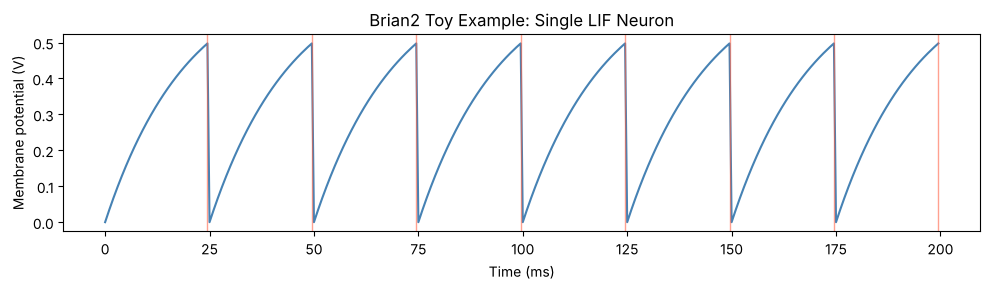

Neuron fired 8 times in 200 ms


In [ ]:
# ============================================================
# Cell 3: Brian2 Toy Example — PROVIDED (just run this)
# A single LIF neuron driven by a Poisson input
# ============================================================
start_scope()  # clear any previous Brian2 objects

# --- Single LIF neuron ---
tau = 20 * ms
toy_eqs = '''
dv/dt = (-v + I_ext) / tau : volt
I_ext : volt  (shared)
'''
toy_neuron = NeuronGroup(1, toy_eqs,
                         threshold='v > 0.5*volt',
                         reset='v = 0*volt',
                         method='euler')
toy_neuron.v = 0 * volt
toy_neuron.I_ext = 0.7 * volt   # constant drive

# --- Monitor voltage and spikes ---
toy_state = StateMonitor(toy_neuron, 'v', record=True)
toy_spikes = SpikeMonitor(toy_neuron)

# --- Run for 200 ms ---
toy_net = Network(toy_neuron, toy_state, toy_spikes)
toy_net.run(200 * ms)

# --- Plot ---
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(toy_state.t / ms, toy_state.v[0] / volt, color='steelblue')
for t_sp in toy_spikes.t / ms:
    ax.axvline(t_sp, color='tomato', alpha=0.6, linewidth=1)
ax.set_xlabel('Time (ms)')
ax.set_ylabel('Membrane potential (V)')
ax.set_title('Brian2 Toy Example: Single LIF Neuron')
plt.tight_layout()
plt.show()
print(f"Neuron fired {toy_spikes.num_spikes} times in 200 ms")

---
## Section 1: Load MNIST Data

Loading MNIST via sklearn (downloads on first use)...


MNIST loaded: 1000 training, 50 test samples.
Training set: (1000, 784)  labels: (1000,)
Test set:     (50, 784)   labels: (50,)


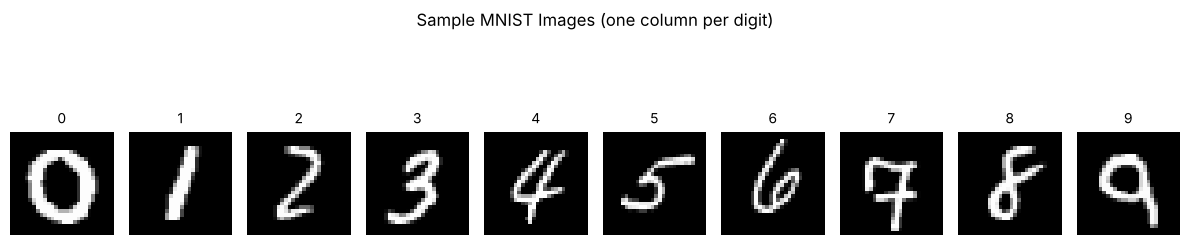

In [ ]:
# ============================================================
# Cell 4: Load MNIST — PROVIDED
# ============================================================
X_train, y_train, X_test, y_test = load_mnist(
    n_train=N_TRAIN, n_test=N_TEST, random_seed=RANDOM_SEED
)

print(f"Training set: {X_train.shape}  labels: {y_train.shape}")
print(f"Test set:     {X_test.shape}   labels: {y_test.shape}")

# Show sample images
show_sample_images(X_train, y_train, n_per_class=1)

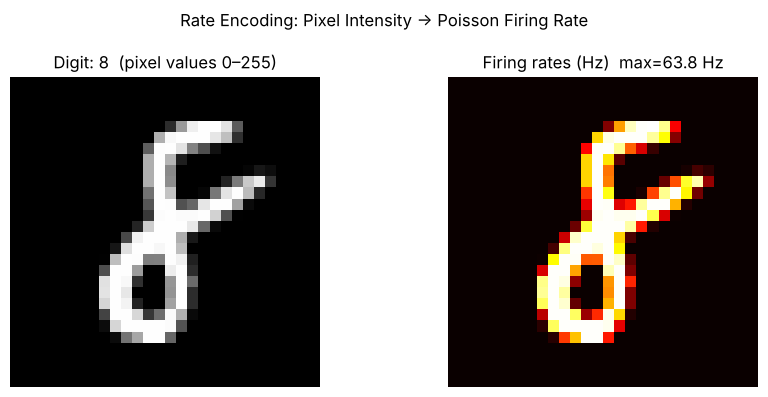

In [ ]:
# ============================================================
# Cell 5: Rate Encoding Visualisation — PROVIDED
# Pixel intensity → Poisson firing rate
# Formula:  rate (Hz) = pixel / 8.0 * INPUT_INTENSITY_BASE
# Max pixel = 255 → max rate = 255/8 * 2.0 ≈ 63.75 Hz
# ============================================================
sample_img = X_train[0].reshape(28, 28)
sample_rates = sample_img / 8.0 * INPUT_INTENSITY_BASE  # Hz

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(sample_img, cmap='gray')
axes[0].set_title(f'Digit: {y_train[0]}  (pixel values 0–255)')
axes[0].axis('off')
axes[1].imshow(sample_rates, cmap='hot')
axes[1].set_title(f'Firing rates (Hz)  max={sample_rates.max():.1f} Hz')
axes[1].axis('off')
plt.suptitle('Rate Encoding: Pixel Intensity → Poisson Firing Rate')
plt.tight_layout()
plt.show()

---
## Section 2: Network Architecture

> **Your task:** Implement each component in TODOs. The equations and Brian2 syntax are scaffolded — focus on understanding *why* each piece exists.

---
## Section 3: Building the Network

### TODO 1 — Excitatory Neuron Group (10 marks)

**Week 4 connection:** In Week 4 you built a LIF neuron:

$$\tau_m \frac{dv}{dt} = -(v - V_{rest}) + R \cdot I$$

Here, the injected current is replaced by **synaptic conductances** `ge` and `gi`:

$$\tau_m \frac{dv}{dt} = -(v - V_{rest}) + g_e(E_{exc} - v) + g_i(E_{inh} - v)$$

$$\frac{dg_e}{dt} = -\frac{g_e}{\tau_{ge}}, \quad \frac{dg_i}{dt} = -\frac{g_i}{\tau_{gi}}$$

$$\frac{d\theta}{dt} = -\frac{\theta}{\tau_\theta} \quad \text{(adaptive threshold — intrinsic plasticity)}$$

- `ge` (excitatory conductance): drives `v` toward `E_EXC = 0 mV` (depolarisation)
- `gi` (inhibitory conductance): drives `v` toward `E_INH = -100 mV` (hyperpolarisation)
- `theta` (adaptive threshold): increases with each spike → homeostatic regulation

This is more **biologically realistic**: real synapses open ion channels whose current depends on the difference between the membrane voltage and the channel's reversal potential. It also naturally prevents the membrane from overshooting the reversal potential, which a fixed-current model cannot guarantee.

**In Brian2 notation** (variables in `volt`, time in `ms`):

```python
eqs_e = '''
    dv/dt = (-(v - V_REST_E*mV) + ge*(E_EXC*mV - v) + gi*(E_INH*mV - v)) / (TAU_M_E*ms) : volt (unless refractory)
    dge/dt = -ge / (TAU_GE*ms)  : 1
    dgi/dt = -gi / (TAU_GI*ms)  : 1
    dtheta/dt = -theta / (TAU_THETA*ms)  : volt  # slow decay (2.8 hours!)
'''
```

**Threshold condition:** `v > (V_THRESH_E - THETA_OFFSET + theta/mV)*mV`  

**Reset:** `v = V_RESET_E*mV; theta += THETA_PLUS*mV`  ← theta increases on every spike

In [ ]:
# ============================================================
# Cell 6: TODO 1 — Excitatory Neuron Group (10 marks)
# ============================================================
start_scope()
defaultclock.dt = DT * ms
np.random.seed(RANDOM_SEED)

# ---- Step a: Define the equation string ----
# Checked the template against the maths in the markdown cell. Two fixes were needed:
#   1. The template used E_INH, which does not exist in config.py — the excitatory
#      reversal potential for inhibition is E_INH_E (-100 mV). Using E_INH gives a
#      NameError when the network is built.
#   2. Added "(unless refractory)" to dv/dt, as in the markdown version, so the
#      membrane potential is held at reset during the 5 ms refractory period
#      (this is how Diehl & Cook implement it too).
# ge and gi are dimensionless conductances (": 1") that multiply a voltage difference,
# so each synaptic term comes out in volts, matching the leak term.

eqs_e = '''
dv/dt     = (-(v - V_REST_E*mV) + ge*(E_EXC*mV - v) + gi*(E_INH_E*mV - v)) / (TAU_M_E*ms) : volt (unless refractory)
dge/dt    = -ge / (TAU_GE*ms)     : 1
dgi/dt    = -gi / (TAU_GI*ms)     : 1
dtheta/dt = -theta / (TAU_THETA*ms) : volt
'''

# ---- Step b: Create the NeuronGroup ----
# Effective threshold = V_THRESH_E - THETA_OFFSET + theta. With theta initialised to
# THETA_INIT (= THETA_OFFSET = 20 mV) the two offsets cancel at the start, so the
# neuron initially fires at exactly V_THRESH_E = -52 mV, and every spike then pushes
# the threshold up by THETA_PLUS = 0.05 mV.
#
# Integration method: I started with method='euler' as in the template, but the
# network blew up after ~80 training images (all 400 neurons firing at the refractory
# limit, v reaching -341 mV, i.e. way below the -100 mV inhibitory reversal potential,
# which is physically impossible). Forward Euler on this equation is only stable while
# dt*(1 + ge + gi)/TAU_M_E < 2, i.e. 1 + ge + gi < 400 with dt = 0.5 ms. Once ~24
# excitatory neurons fire in the same timestep, every other neuron receives
# gi += 24*17 > 400 and the Euler step overshoots, which makes more neurons fire,
# which adds more inhibition... a numerical seizure. Exponential Euler solves each
# variable's (conditionally linear) ODE exactly over the step, so v can never
# overshoot a reversal potential and the scheme is stable for any conductance.
# DT in config.py is unchanged. See the note below this cell.

exc_neurons = NeuronGroup(
    N_EXCITATORY,
    model=eqs_e,
    threshold='v > (V_THRESH_E - THETA_OFFSET + theta/mV)*mV',
    reset='v = V_RESET_E*mV; theta += THETA_PLUS*mV',
    refractory=REFRAC_E*ms,
    method='exponential_euler'
)

# ---- Step c: Set initial conditions ----
exc_neurons.v      = V_REST_E * mV
exc_neurons.ge     = 0
exc_neurons.gi     = 0
exc_neurons.theta  = THETA_INIT * mV

print(f"Excitatory group created: {N_EXCITATORY} neurons")


Excitatory group created: 400 neurons


> **Note on the integration method (my addition).** With `method='euler'` the simulation was fine for the first ~80 images and then went into a runaway state: every excitatory neuron fired once per refractory period for the rest of training (36,400 spikes per 500 ms instead of ~15), `gi` reached several thousand and `v` dropped to −341 mV. A conductance-based neuron can never go below its most negative reversal potential (−100 mV here), so this is a numerical artefact, not biology. The forward-Euler update for `v` is `v += dt/τ·[…]` with an effective decay rate of `(1 + ge + gi)/τ_m`; it is only stable if `dt·(1 + ge + gi)/τ_m < 2`, i.e. `1 + ge + gi < 400` for `dt = 0.5 ms`, `τ_m = 100 ms`. One inhibitory spike adds 17 to `gi`, so about 24 excitatory neurons firing in the same 0.5 ms step is enough to break it — and once a few neurons share a receptive field for the same digit this happens at stimulus onset. Because `dt` lives in `config.py` (which must not be changed), I switched the neuron groups to `exponential_euler`, which is exact for each conditionally-linear ODE over a step and unconditionally stable. All parameter values are unchanged.

### TODO 2 — Inhibitory Neuron Group (10 marks)

Build a simpler conductance-based LIF NeuronGroup for the inhibitory population.

Differences from the excitatory group:
   - NO adaptive threshold (no dtheta/dt, no theta increment in reset)

Why faster time constant? Inhibitory neurons need to respond quickly to
suppress the excitatory population and create winner-take-all dynamics.

Use the **inhibitory parameters** from `config.py`: `V_REST_I`, `V_RESET_I`, `V_THRESH_I`, `TAU_M_I`, `REFRAC_I`.

In [ ]:
# ============================================================
# Cell 7: TODO 2 — Inhibitory Neuron Group (10 marks)
# ============================================================

# ---- Step a: Define the equation string ----
# Same conductance-based LIF as the excitatory group but with the inhibitory
# parameters (TAU_M_I = 10 ms, so 10x faster; V_REST_I = -60 mV; E_INH_I = -85 mV)
# and no adaptive threshold — these neurons just relay the "winner" signal, they
# don't need to specialise, so no theta.

eqs_i = '''
dv/dt  = (-(v - V_REST_I*mV) + ge*(E_EXC*mV - v) + gi*(E_INH_I*mV - v)) / (TAU_M_I*ms) : volt (unless refractory)
dge/dt = -ge / (TAU_GE*ms) : 1
dgi/dt = -gi / (TAU_GI*ms) : 1
'''

# ---- Step b: Create the NeuronGroup ----
# Fixed threshold at V_THRESH_I = -40 mV, reset to V_RESET_I = -45 mV (only 5 mV
# below threshold, so these neurons can fire again very quickly), 2 ms refractory.

inh_neurons = NeuronGroup(
    N_INHIBITORY,
    model=eqs_i,
    threshold='v > V_THRESH_I*mV',
    reset='v = V_RESET_I*mV',
    refractory=REFRAC_I*ms,
    method='exponential_euler'   # same reasoning as the excitatory group
)

# ---- Step c: Set initial conditions ----
inh_neurons.v  = V_REST_I * mV
inh_neurons.ge = 0
inh_neurons.gi = 0

print(f"Inhibitory group created: {N_INHIBITORY} neurons")


Inhibitory group created: 400 neurons


### TODO 3 — Input→Excitatory STDP Synapses (25 marks)

**Trace variables (provided):**

Each synapse maintains three exponentially-decaying trace variables:

$$\frac{d\,\text{pre}}{dt} = -\frac{\text{pre}}{\tau_{\text{pre}}} \qquad \frac{d\,\text{post1}}{dt} = -\frac{\text{post1}}{\tau_{\text{post1}}} \qquad \frac{d\,\text{post2}}{dt} = -\frac{\text{post2}}{\tau_{\text{post2}}}$$

- `pre` — tracks recent pre-synaptic activity (decays with `TAU_STDP_PRE`)
- `post1` — fast post-synaptic trace used for **LTD** detection (decays with `TAU_POST1`)
- `post2` — slow post-synaptic trace used for **LTP** detection (decays with `TAU_POST2`)
- `post2before` — snapshot of `post2` taken **at the moment the post neuron fires**, before it is reset; this ensures LTP uses the trace value that reflects *prior* post-synaptic activity, not the freshly reset value

All traces are declared `(event-driven)` in Brian2, meaning they are only updated at spike events rather than every timestep — this is computationally more efficient for sparse spiking networks.

> NOTE

**LTP/LTD asymmetry:**  
`LTP_RATE = 0.01` vs `LTD_RATE = 0.0001` — LTP is 100× stronger per event. This asymmetry is intentional: since a pre-spike triggers LTD on *every* pre-spike (which are frequent), while LTP only fires on post-spikes (which are sparser), the rates are tuned so the net weight change remains balanced and weights do not collapse to zero.

**Weight initialisation:**

All `N_INPUT × N_EXCITATORY` synapses are connected all-to-all. Initial weights are drawn from:

$$w_{\text{init}} = \text{Uniform}(0,\,1) \times 0.3 + 0.003 \quad \Rightarrow \quad w_{\text{init}} \in (0.003,\ 0.303]$$

then clipped to `[W_MIN, W_MAX]`. The small offset (`+0.01`) prevents exact-zero weights, and the scaling factor (`×0.3`) keeps initial weights weak so the network can learn from scratch.

In [ ]:
# ============================================================
# Cell 8: TODO 3 — Input→Excitatory STDP Synapses (25 marks)
# ============================================================

# ---- Step a: Create the input PoissonGroup ----
# Starts with zero rates; rates are set dynamically in the training loop.
input_group = PoissonGroup(N_INPUT, rates=np.zeros(N_INPUT) * Hz)

# ---- STDP model string: trace variables (PROVIDED) ----
# The two exponentially-decaying traces are provided for you.
# w is the synaptic weight (dimensionless, range [W_MIN, W_MAX]).
stdp_model = '''
w         : 1
dpre/dt  = -pre  / (TAU_STDP_PRE*ms)  : 1 (event-driven)
dpost1/dt     = -post1 / (TAU_POST1*ms)       : 1 (event-driven)
dpost2/dt     = -post2 / (TAU_POST2*ms)       : 1 (event-driven)
post2before   : 1
'''

# ---- Step b: Write on_pre ----
# A pre (input) spike arrives:
#   1. it opens the excitatory conductance of the post neuron by the weight,
#   2. it marks "a pre spike just happened" by resetting the pre trace to 1,
#   3. LTD: if the post neuron fired recently, post1 is still large, so this pre
#      spike is anti-causal (post before pre) -> weaken the synapse a little.
# clip() keeps w inside [W_MIN, W_MAX].

stdp_on_pre = '''
ge_post += w
pre = 1
w = clip(w - LTD_RATE * post1, W_MIN, W_MAX)
'''

# ---- Step c: Write on_post ----
# The post (excitatory) neuron fires:
#   1. snapshot the slow trace post2 BEFORE it is reset (otherwise it would always be 1),
#   2. LTP: pre is large if an input spike came in just before -> causal -> strengthen.
#      Multiplying by post2before makes the update triplet-like: the potentiation is
#      bigger if the post neuron was already active recently.
#   3. reset both post traces.

stdp_on_post = '''
post2before = post2
w = clip(w + LTP_RATE * pre * post2before, W_MIN, W_MAX)
post1 = 1
post2 = 1
'''

# ---- Step d: Create the Synapses object ----
stdp_synapses = Synapses(
    input_group, exc_neurons,
    model=stdp_model,
    on_pre=stdp_on_pre,
    on_post=stdp_on_post
)

# ---- Step e: Connect all-to-all and initialise weights ----
# connect() with no arguments = every input to every excitatory neuron (784 x 400).
# Weights: (Uniform(0,1) + 0.01) * 0.3  ->  in (0.003, 0.303], then clipped.
stdp_synapses.connect()
w_init = np.random.random(N_INPUT * N_EXCITATORY) + 0.01
w_init *= 0.3
stdp_synapses.w = np.clip(w_init, W_MIN, W_MAX)

print(f"STDP synapses created: {len(stdp_synapses.w):,} connections")
print(f"Initial weights: mean={np.mean(stdp_synapses.w):.3f}, "
      f"min={np.min(stdp_synapses.w):.3f}, max={np.max(stdp_synapses.w):.3f}")


STDP synapses created: 313,600 connections
Initial weights: mean=0.153, min=0.003, max=0.303


> **Why `post2before`?** `post2` is reset to 1 on every post-spike. Without snapshotting it first, LTP would always multiply by 1 regardless of actual prior activity, losing the timing-dependence entirely.

---

### TODO 4 — Fixed Synapses: Excitatory↔Inhibitory (5 marks)

Two fixed (non-plastic) synapse objects implement the winner-take-all circuit:

**Exc → Inh (one-to-one):**  Neuron `i` in the excitatory layer activates neuron `i` in the inhibitory layer. Connection condition: `'i == j'`. Weight: `W_EXC_TO_INH`. Effect: `ge_post += W_EXC_TO_INH * mV`

**Inh → Exc (lateral inhibition):**  Each inhibitory neuron suppresses **all excitatory neurons except its partner**. Connection condition: `'i != j'`. Weight: `W_INH_TO_EXC`. Effect: `gi_post += W_INH_TO_EXC * mV`

> Why `i != j`? Neuron `j` just fired (triggering its inhibitory partner `j`). We don't want to inhibit the winner — only the competitors.

In [ ]:
# ============================================================
# Cell 9: TODO 4 — Fixed Exc↔Inh Synapses (5 marks)
# ============================================================
# Note on units: ge and gi were declared dimensionless (": 1") in both neuron
# models and are multiplied by a voltage inside dv/dt. So the weight has to be
# added as a plain number — writing "ge_post += W_EXC_TO_INH*mV" (as the hint
# suggests) raises a DimensionMismatchError in Brian2. The numbers themselves
# (10.4 and 17) are the Diehl & Cook values and work as-is.

# ---- Part A: Excitatory → Inhibitory (one-to-one) ----
exc_to_inh = Synapses(
    exc_neurons, inh_neurons,
    on_pre='ge_post += W_EXC_TO_INH'
)
exc_to_inh.connect(condition='i == j')

# ---- Part B: Inhibitory → Excitatory (lateral inhibition) ----
# gi_post, not ge_post — this is the inhibitory conductance. Every inhibitory
# neuron projects to all excitatory neurons except its own partner (i != j),
# so the neuron that just won is not punished, only its competitors.
inh_to_exc = Synapses(
    inh_neurons, exc_neurons,
    on_pre='gi_post += W_INH_TO_EXC'
)
inh_to_exc.connect(condition='i != j')

print(f"Exc→Inh synapses: {exc_to_inh.N[:].sum()} (should be {N_EXCITATORY})")
print(f"Inh→Exc synapses: {inh_to_exc.N[:].sum()} (should be {N_INHIBITORY*(N_INHIBITORY-1)})")


Exc→Inh synapses: 400 (should be 400)
Inh→Exc synapses: 159600 (should be 159600)


---
## Section 4: Training

### TODO 5 — Training Loop (15 marks)

**How training works:**
1. Before each image: normalize input weights so each excitatory neuron receives a fixed total drive
2. For each image: convert pixels to firing rates, set `input_group.rates`
3. Run simulation for `PRESENTATION_TIME` ms — STDP updates weights
4. Set rates to zero, run for `REST_TIME` ms
5. Check total spike count; if too low, re-present the same image with boosted intensity

**Why the rest period?**  
During rest, synaptic traces (`x_pre`, `x_post`) decay toward zero. This prevents the STDP update from one image interfering with the next — it acts as a "memory reset" between stimuli, mirroring the inter-stimulus interval in biological experiments.

**Rate encoding formula:**
$$\text{rate (Hz)} = \frac{\text{pixel}}{8.0} \times \text{INPUT\_INTENSITY\_BASE}$$

Maximum pixel = 255 → max rate ≈ 63.75 Hz. This moderate rate avoids saturating the network.

**Adaptive Input Intensity (Diehl & Cook, 2015)**

If the total number of excitatory spikes elicited during a single image presentation falls below a threshold ($\theta_{\min} = 5$ spikes), the network is deemed to have not responded meaningfully. In this case, the same image is re-presented with an increased input intensity ($\lambda \rightarrow \lambda + \Delta\lambda$, capped at $\lambda_{\max} = 32$), which scales the Poisson firing rates of all input neurons proportionally. This retry loop repeats for up to 5 attempts per image. Once the spike count exceeds $\theta_{\min}$, $\lambda$ resets to its baseline value for the next image. This mechanism ensures that every training sample produces a detectable network response, thereby preventing silent periods during which no STDP weight updates would occur.

---

**Weight Normalization**

Prior to each image presentation, the input→excitatory synaptic weights are rescaled so that each excitatory neuron receives a fixed total synaptic drive. Specifically, for each excitatory neuron $j$, all incoming weights $\{w_{ij}\}$ are multiplied by the factor:

$$\frac{W_{\text{target}}}{\sum_i w_{ij}}, \quad W_{\text{target}} = 78.0$$

This ensures that the summed afferent weight onto every excitatory neuron remains constant at $W_{\text{target}}$, regardless of the history of STDP updates. The normalization prevents individual neurons from accumulating disproportionately large weights — a form of runaway potentiation — while complementing STDP by maintaining competitive balance across the excitatory population.

In [ ]:
# ============================================================
# Cell 10: Assemble Network and Monitors — PROVIDED
# ============================================================

# Spike monitor for excitatory neurons (records during training)
spike_mon = SpikeMonitor(exc_neurons)

# Assemble all objects into a single Network
net = Network(
    input_group,
    exc_neurons, inh_neurons,
    stdp_synapses,
    exc_to_inh, inh_to_exc,
    spike_mon
)

def normalize_weights(synapses, n_input, n_exc, target_sum=78.0):
    w_matrix = np.zeros((n_input, n_exc))
    w_matrix[synapses.i[:], synapses.j[:]] = synapses.w[:]
    col_sums = np.sum(w_matrix, axis=0)
    col_sums[col_sums == 0] = 1
    col_factors = target_sum / col_sums
    for j in range(n_exc):
        w_matrix[:, j] *= col_factors[j]
    synapses.w[:] = w_matrix[synapses.i[:], synapses.j[:]]

print("Network assembled. Objects:", [type(o).__name__ for o in net.objects])

Network assembled. Objects: ['SpikeMonitor', 'NeuronGroup', 'Synapses', 'Synapses', 'Synapses', 'PoissonGroup', 'NeuronGroup']


In [ ]:
# ============================================================
# Cell 11: TODO 5 — Training Loop (15 marks)
# ============================================================

# Arrays to accumulate spike counts during training
spike_counts_train = np.zeros((N_TRAIN, N_EXCITATORY), dtype=int)
previous_spike_count = np.zeros(N_EXCITATORY, dtype=int)
training_accuracies = []
input_intensity      = INPUT_INTENSITY_BASE

print(f"Starting training on {N_TRAIN} images...")
print(f"Each image: {PRESENTATION_TIME} ms presentation + {REST_TIME} ms rest")
print("="*60)

import time
t_start = time.time()
n_retries = 0   # just to see how often the intensity boost actually kicks in

for i in range(N_TRAIN):

    normalize_weights(stdp_synapses, N_INPUT, N_EXCITATORY, target_sum=78.0)

    counter = 0
    while counter<5:

        # ---- Step a: Compute firing rates for this image ----
        # pixel 255 -> 255/8 * 2 = 63.75 Hz at base intensity; input_intensity is
        # bumped up by the retry logic below if the network stays silent.
        rates_hz = X_train[i] / 8.0 * input_intensity

        # ---- Step b: Set the input PoissonGroup rates ----
        input_group.rates = rates_hz * Hz

        # ---- Step c: Run for PRESENTATION_TIME ----
        net.run(PRESENTATION_TIME * ms)

        # ---- Step d: Record spikes fired during this presentation ----
        current_spike_count  = np.array(spike_mon.count) - previous_spike_count
        previous_spike_count = np.copy(spike_mon.count)

        # ---- Step e: Rest period ----
        # Silence the input and let the membrane potentials, conductances and
        # STDP traces decay back towards zero before the next image.
        input_group.rates = np.zeros(N_INPUT) * Hz
        net.run(REST_TIME * ms)

        # ---- Decision point ----
        if np.sum(current_spike_count) < MIN_SPIKES_THRESHOLD:
            # Too silent → boost and retry the SAME image
            input_intensity = min(input_intensity + 1, 32)
            counter += 1
            n_retries += 1

        else:
            # Enough spikes → record and move to next image
            spike_counts_train[i] = current_spike_count.astype(int)
            input_intensity = INPUT_INTENSITY_BASE  # reset for next image
            counter += 1
            break

    if np.sum(current_spike_count) > 0:
        spike_counts_train[i] = current_spike_count.astype(int)

    # ---- Logging (provided) ----
    if (i + 1) % BATCH_LOG_INTERVAL == 0:
        assignments = assign_neuron_labels(spike_counts_train[:i+1], y_train[:i+1])
        preds = predict_from_spikes(spike_counts_train[:i+1], assignments)
        acc = compute_accuracy(y_train[:i+1], preds)
        training_accuracies.append(acc)
        elapsed = time.time() - t_start
        print(f"  [{i+1:>4}/{N_TRAIN}] Training accuracy so far: {acc:.1%}   "
              f"(mean spikes/image: {spike_counts_train[:i+1].sum(axis=1).mean():.1f}, "
              f"{elapsed/60:.1f} min elapsed)")

print("="*60)
print("Training complete.")
print(f"Total wall-clock time: {(time.time()-t_start)/60:.1f} min, "
      f"intensity boosts needed: {n_retries}")


Starting training on 1000 images...
Each image: 350.0 ms presentation + 150.0 ms rest


  [  50/1000] Training accuracy so far: 60.0%   (mean spikes/image: 16.0, 0.6 min elapsed)


  [ 100/1000] Training accuracy so far: 56.0%   (mean spikes/image: 17.2, 1.1 min elapsed)


  [ 150/1000] Training accuracy so far: 55.3%   (mean spikes/image: 17.2, 1.7 min elapsed)


  [ 200/1000] Training accuracy so far: 59.5%   (mean spikes/image: 17.2, 2.2 min elapsed)


...

  [ 800/1000] Training accuracy so far: 61.9%   (mean spikes/image: 17.4, 9.4 min elapsed)


  [ 850/1000] Training accuracy so far: 62.7%   (mean spikes/image: 17.4, 10.0 min elapsed)


  [ 900/1000] Training accuracy so far: 63.6%   (mean spikes/image: 17.5, 10.6 min elapsed)


  [ 950/1000] Training accuracy so far: 64.0%   (mean spikes/image: 17.7, 11.2 min elapsed)


  [1000/1000] Training accuracy so far: 63.6%   (mean spikes/image: 17.6, 11.8 min elapsed)
Training complete.
Total wall-clock time: 11.8 min, intensity boosts needed: 21


Neurons per class:
  Digit 0: 65 neurons
  Digit 1: 15 neurons
  Digit 2: 66 neurons
  Digit 3: 46 neurons
  Digit 4: 33 neurons
  Digit 5: 39 neurons
  Digit 6: 33 neurons
  Digit 7: 34 neurons
  Digit 8: 44 neurons
  Digit 9: 25 neurons


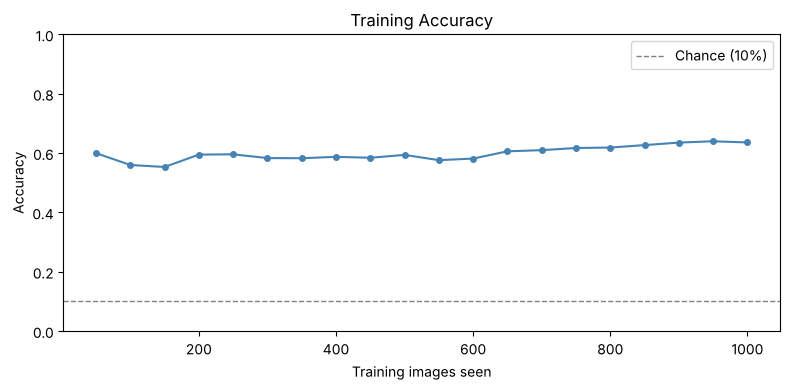

In [ ]:
# ============================================================
# Cell 12: Assign Neuron Labels After Training — PROVIDED
# ============================================================
# After training, each excitatory neuron is assigned to the digit
# class it responded to most strongly on average.
assignments = assign_neuron_labels(spike_counts_train, y_train)
print("Neurons per class:")
for c in range(10):
    print(f"  Digit {c}: {np.sum(assignments == c)} neurons")

# Plot training accuracy curve
if training_accuracies:
    plot_training_progress(training_accuracies, BATCH_LOG_INTERVAL)

---
## Section 5: Testing

### TODO 6 — Test Phase (15 marks)

During testing:
- **STDP must be disabled** — we do not want weights to change while evaluating accuracy
- Run the same presentation loop as training, but on test images
- Use `predict_from_spikes()` with the learned `assignments` to classify each image

**To disable STDP:** set `LTP_RATE` and `LTD_RATE` to 0 in the synapse namespace:
```python
stdp_synapses.namespace['LTP_RATE'] = 0.0
stdp_synapses.namespace['LTD_RATE'] = 0.0
```

In [ ]:
# ============================================================
# Cell 13: TODO 6 — Test Phase (15 marks)
# ============================================================

# ---- Step a: Disable STDP ----
# The on_pre/on_post code still runs, but with both rates at zero the weight
# update becomes w = clip(w + 0, ...) i.e. the weights are frozen. Setting these
# in the Synapses object's own namespace overrides the values imported from config.
stdp_synapses.namespace['LTP_RATE'] = 0.0
stdp_synapses.namespace['LTD_RATE'] = 0.0

# Also freeze the weight snapshot so I can check nothing changed during testing.
w_before_test = np.array(stdp_synapses.w)

# Array to collect test spike counts
spike_counts_test = np.zeros((N_TEST, N_EXCITATORY), dtype=int)

print(f"Starting test phase on {N_TEST} images (STDP disabled)...")

for i in range(N_TEST):

    # ---- Step b: Rate encoding (same formula as training) ----
    rates_hz = X_test[i] / 8.0 * INPUT_INTENSITY_BASE

    # ---- Step c: Set input rates ----
    input_group.rates = rates_hz * Hz

    count_before = np.array(spike_mon.count)

    # ---- Step d: Run presentation ----
    net.run(PRESENTATION_TIME * ms)

    spike_counts_test[i] = np.array(spike_mon.count) - count_before

    # Rest period
    input_group.rates = np.zeros(N_INPUT) * Hz
    net.run(REST_TIME * ms)

# sanity check that the weights really were frozen
print(f"Max weight change during testing: {np.max(np.abs(np.array(stdp_synapses.w) - w_before_test)):.2e}")
print(f"Test images with zero excitatory spikes: {np.sum(spike_counts_test.sum(axis=1) == 0)} / {N_TEST}")

# ---- Step e: Classify and report accuracy ----
y_pred = predict_from_spikes(spike_counts_test, assignments)
accuracy = compute_accuracy(y_test, y_pred)

print(f"\nTest accuracy: {accuracy:.1%}")
classification_report_snn(y_test, y_pred)


Starting test phase on 50 images (STDP disabled)...


Max weight change during testing: 0.00e+00
Test images with zero excitatory spikes: 0 / 50

Test accuracy: 64.0%
Class       Correct    Total   Accuracy
----------------------------------------
0                 4        5      80.0%
1                 4        4     100.0%
2                 2        3      66.7%
3                 5        8      62.5%
4                 1        3      33.3%
5                 5        6      83.3%
6                 2        2     100.0%
7                 3        6      50.0%
8                 3        6      50.0%
9                 3        7      42.9%
----------------------------------------
Overall                   50      64.0%


'Class       Correct    Total   Accuracy\n----------------------------------------\n0                 4        5      80.0%\n1                 4        4     100.0%\n2                 2        3      66.7%\n3                 5        8      62.5%\n4                 1        3      33.3%\n5                 5        6      83.3%\n6                 2        2     100.0%\n7                 3        6      50.0%\n8                 3        6      50.0%\n9                 3        7      42.9%\n----------------------------------------\nOverall                   50      64.0%'

---
## Section 6: Visualisation

### Spike Raster and Firing Rate Distribution

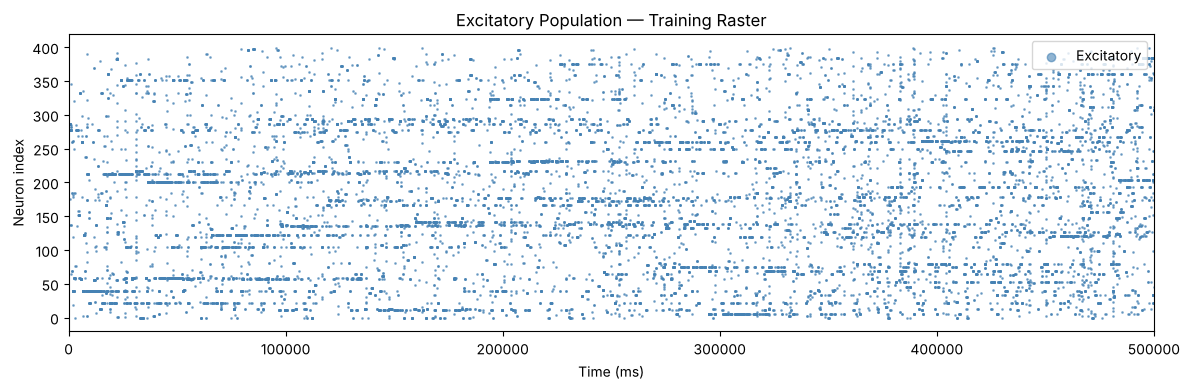

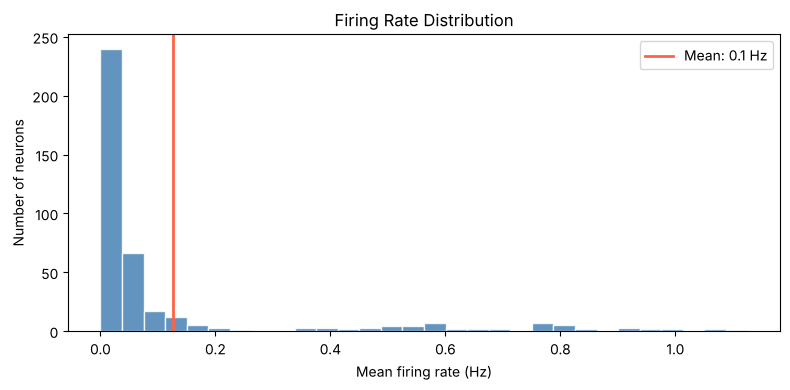

Firing rates — Mean: 0.13 Hz, Max: 1.13 Hz, Silent neurons: 8


In [ ]:
# ============================================================
# Cell 14: Spike Raster + Firing Rate Distribution (PROVIDED) (2 marks)
# ============================================================

# ---- Spike raster plot ----
# Call plot_spike_raster() to visualise excitatory neuron spikes.

plot_spike_raster(
      spike_times  = {'Excitatory': spike_mon.t / ms},
      spike_neurons= {'Excitatory': spike_mon.i},
      duration_ms  = N_TRAIN * (PRESENTATION_TIME + REST_TIME),
      title        = 'Excitatory Population — Training Raster'
  )

plot_firing_rate_distribution(spike_counts_train.sum(axis=0), N_TRAIN * PRESENTATION_TIME)

**Observation.** Activity is very sparse: on average about 17 excitatory spikes per image across the whole population of 400 (mean rate 0.13 Hz, max 1.1 Hz), with typically 2–10 neurons active for any given image. That is the winner-take-all circuit doing its job — one neuron fires, its inhibitory partner suppresses the other 399, and the input has to "re-earn" the next spike. The horizontal streaks in the raster are single neurons winning a run of consecutive images and then going quiet as their adaptive threshold θ climbs, which is the hand-over to other neurons that intrinsic plasticity is supposed to produce. The firing-rate histogram is strongly skewed, though: most neurons fired only a handful of times in the whole run and a minority of ~30 did most of the firing, so after 1000 images the load is far from evenly spread yet.

### Weight Receptive Fields

WARNING    /home/claude/work/submission/utils/plotting.py:67: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
 [py.warnings]


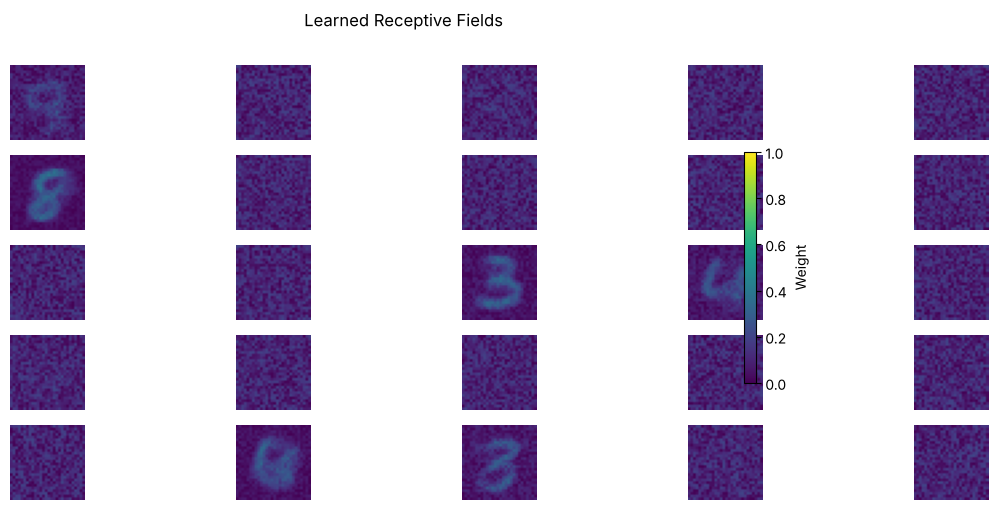

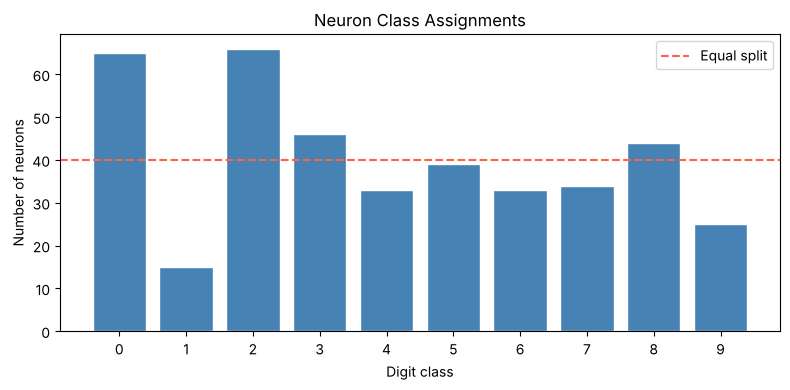

In [ ]:
# ============================================================
# Cell 15: Weight Receptive Fields (PROVIDED) (3 marks)
# ============================================================

# ---- Part A: Receptive field visualisation ----
# The weight matrix from Input → Excitatory neurons has shape (N_INPUT, N_EXCITATORY).
# Each column is the set of weights from all 784 inputs to one excitatory neuron —
# reshaped to 28×28, it shows what pattern that neuron has learned to respond to.

weights = np.array(stdp_synapses.w).reshape(N_INPUT, N_EXCITATORY)
plot_weight_receptive_fields(weights, n_input=N_INPUT, n_show=25)

# This shows how many excitatory neurons were assigned to each digit class.
plot_neuron_assignments(assignments)

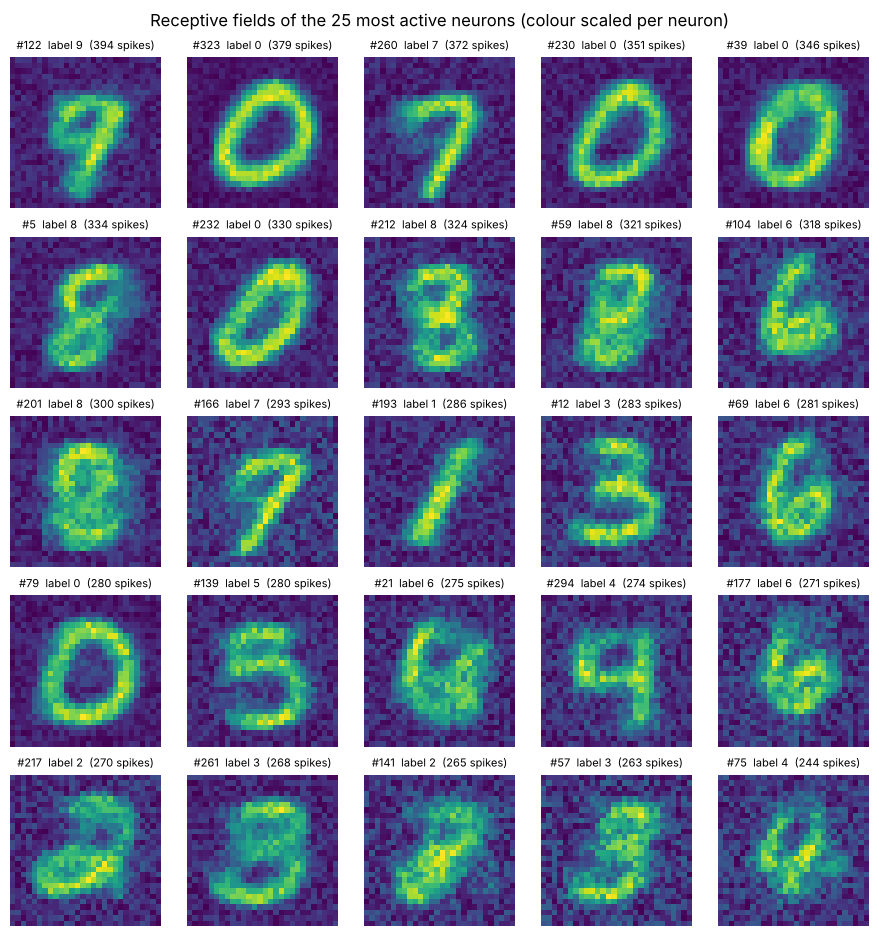

Weight stats after training: mean=0.100, max=0.456, fraction of weights > 0.5: 0.00%, fraction == 0: 0.0%
Neurons that fired fewer than 5 times in the whole training run: 84 / 400
Share of all training spikes produced by the 25 most active neurons: 43.1%
Median spikes per neuron over training: 10, max: 394


In [ ]:
# ============================================================
# Extra (my addition): a closer look at the receptive fields
# ============================================================
# The provided plot uses a fixed colour scale of 0..1, but after normalising every
# column to a sum of 78 the typical weight is only 78/784 ~ 0.1, so even a well-formed
# receptive field looks faint on that scale. Here I take the 25 neurons that fired the
# most during training (the ones that actually "won" images and therefore learned),
# scale the colour per neuron, and label each with the digit class it was assigned to.
total_spikes = spike_counts_train.sum(axis=0)
top = np.argsort(total_spikes)[::-1][:25]

fig, axes = plt.subplots(5, 5, figsize=(9, 9.5))
for ax, n in zip(axes.flat, top):
    rf = weights[:, n].reshape(28, 28)
    ax.imshow(rf, cmap='viridis', vmin=0, vmax=rf.max())
    ax.set_title(f"#{n}  label {assignments[n]}  ({total_spikes[n]} spikes)", fontsize=8)
    ax.axis('off')
plt.suptitle('Receptive fields of the 25 most active neurons (colour scaled per neuron)')
plt.tight_layout()
plt.show()

print(f"Weight stats after training: mean={weights.mean():.3f}, max={weights.max():.3f}, "
      f"fraction of weights > 0.5: {(weights > 0.5).mean():.2%}, fraction == 0: {(weights == 0).mean():.1%}")
print(f"Neurons that fired fewer than 5 times in the whole training run: {(total_spikes < 5).sum()} / {N_EXCITATORY}")
print(f"Share of all training spikes produced by the 25 most active neurons: {total_spikes[top].sum() / total_spikes.sum():.1%}")
print(f"Median spikes per neuron over training: {np.median(total_spikes):.0f}, max: {total_spikes.max()}")


---
## Section 7: Written Analysis

### TODO 7 — Written Analysis (15 marks)

Answer all five questions in the Markdown cell below.
Refer to the **Assignment Sheet** for the full question text.
Each question is worth 3 marks. Aim for 3–5 sentences per question.


**TODO 7 — Written Analysis**

---

**Q1. Adaptive threshold (θ)**

θ is added to each excitatory neuron's firing threshold, and every spike increases it by 0.05 mV. Because τ_θ is 10⁷ ms, it barely decays during training, so a neuron that fires a lot becomes permanently harder to fire. This is intrinsic plasticity: it changes the neuron's own excitability, not its synapses. Without θ, the first neurons to respond would be strengthened by STDP and end up winning every image (a rich-get-richer effect). θ forces these winners to step back so that other neurons get a chance to learn. In my results this worked: the raster shows neurons winning a run of images and then going quiet, all ten digits received neurons (15–66 each), and only 8 of 400 neurons stayed silent.

---

**Q2. LTP/LTD asymmetry**

LTD is applied on every presynaptic spike, and a bright pixel fires at up to 64 Hz, so each synapse sees many pre-spikes per image. LTP only happens when the postsynaptic neuron fires, which is rare because of winner-take-all inhibition. In my run there were only about 17 excitatory spikes per image across 400 neurons. LTD events therefore greatly outnumber LTP events, and the 100× larger LTP rate balances this so useful weights can grow. If LTP_RATE = LTD_RATE = 0.005, LTD would be 50× stronger than now. The weights from active pixels driving each neuron would be eroded, and normalisation would shift weight onto background pixels. Receptive fields would become flat and unselective, and accuracy would drop towards chance.

---

**Q3. Receptive field interpretation**

In the provided plot, only a few of the 25 fields show clear digits; the rest look like noise. Partly this is a display issue: after normalisation the average weight is about 0.1 (max 0.46), so the 0–1 colour scale makes everything look faint. When I plotted the 25 most active neurons with per-neuron colour scaling, all of them showed clear digits matching their assigned labels. STDP produced this because when a neuron wins an image, the stroke pixels have just fired, so their pre-trace is high and those synapses receive LTP, while background pixels receive nothing. The noisy fields belong to the 84 neurons that fired fewer than 5 times. Training on more images would let them learn.

---

**Q4. Accuracy and an improvement**

My test accuracy was 64.0% on 50 test images, far above the 10% chance level. Training accuracy was similar (63.6%), so the network is under-trained rather than overfitting. Digits 1 and 6 were classified perfectly, while 4 and 9 were weakest, probably because they share similar strokes. The change I would make is training on many more images, ideally the full 60,000 MNIST set, as Diehl & Cook did to reach about 83%. Biologically, STDP is slow and incremental: each spike changes a weight only slightly, and real sensory neurons refine their receptive fields over thousands of exposures. After 1000 images, the median neuron had fired only 10 times. More training would let quiet neurons specialise and produce cleaner digit prototypes.

---

**Q5. STDP vs Hebbian learning**

Hebbian learning strengthens a synapse whenever the pre- and postsynaptic neurons are active together, regardless of which fired first, so it only detects correlation. STDP depends on precise spike timing. If the presynaptic neuron fires shortly before the postsynaptic one, the synapse is strengthened (LTP). If it fires after, the synapse is weakened (LTD). This matters because an input that fires before the postsynaptic spike may have helped cause it, while an input that fires afterwards could not have. STDP therefore learns causal, predictive relationships rather than mere co-occurrence. The LTD side also adds competition between synapses, preventing the unlimited weight growth of plain Hebbian learning. In this network, that keeps the weights of digit stroke pixels while weakening irrelevant ones.


---

## Beyond the Assignment

This assignment gave you hands-on experience building a biologically plausible SNN and training it with an unsupervised learning rule — no labels, no backpropagation, just spike timing.

Once you have a working implementation, we encourage you to **experiment freely**. Some things worth trying:

- Train for more images (`N_TRAIN`) and observe how receptive fields become sharper
- Adjust `LTP_RATE` / `LTD_RATE` and see how the weight distribution changes
- Change `N_EXCITATORY` (e.g. 100 vs 800) and observe the effect on accuracy and specialisation
- Vary `PRESENTATION_TIME` or `REST_TIME` and explore how trace dynamics affect learning
- Try a different digit subset and see which classes are easiest to separate

SNNs remain an **active research area** — efficient training algorithms, hardware implementations on neuromorphic chips, and combined IP+STDP rules are all open problems. If you discover something interesting, notice unexpected behaviour, or have thoughts on what could be improved, **we would love to hear from you**.
